# C3 DistilBERT — phần Nhật Huy trong lượt chạy chung
Ba seed 42, 123, 2026 thuộc pipeline cục bộ A/B/C. Notebook kiểm config/hash,
suy luận thật validation/test và tổng hợp kết quả. Không thay bằng bộ C3 riêng
ngày 08/10 hoặc bảng báo cáo 2.1; không huấn luyện thêm khi Run All.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import torch
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/notebook_support.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.notebook_support import artifacts_root, benchmark, replay_split
from src.datasets.goemotions import multi_hot, sha256, REVISION
from src.evaluation.protocols import read_json, validate_protocol
from src.evaluation.metrics import evaluate_multilabel
from src.models.transformer import METRIC_NAMES, run_folder, load_transformer_run
from scripts.analysis.summarize_project import summarize
ARTIFACTS = artifacts_root()
verified, frames, names = benchmark(str(ARTIFACTS))
SEEDS = (42, 123, 2026)
torch.set_num_threads(4)
print('Python:', sys.version.split()[0], '| torch:', torch.__version__)
print('Thiết bị suy luận:', 'CUDA' if torch.cuda.is_available() else 'CPU')
print('Revision dữ liệu:', REVISION)

PASS A: 12 dòng từ scores thật


PASS B: 6 dòng từ scores thật


PASS C: bert seed 42


PASS C: bert seed 123


PASS C: bert seed 2026


...

PASS C: distilbert seed 42


PASS C: distilbert seed 123


PASS C: distilbert seed 2026


Python: 3.12.6 | torch: 2.11.0+cu128


Thiết bị suy luận: CUDA
Revision dữ liệu: add492243ff905527e67aeb8b80c082af02207c3


## 1. Cấu hình và ba checkpoint full
Mỗi seed bắt đầu từ DistilBERT pretrained, học 28 logits bằng BCE và chọn epoch bằng
Macro-F1 validation tại 0,5. Muốn tạo checkpoint: chạy
`python -m scripts.transformers.run_transformer_seeds --architectures distilbert --device cuda --resume`.
Lệnh train được chạy riêng; cell dưới chỉ kiểm các run đã hoàn tất.

In [2]:
runs, receipts = {}, []
for seed in SEEDS:
    folder = run_folder(ARTIFACTS, 'distilbert', seed)
    meta = load_transformer_run(folder, require_full=True)
    assert meta['architecture'] == 'distilbert' and meta['seed'] == seed
    protocol = read_json(folder/'final_protocol.json')
    validate_protocol(folder, protocol, names)
    runs[seed] = meta
    receipts.append(dict(seed=seed, selected_epoch=meta['selected_epoch'],
        n_train=meta['sizes']['train'], n_validation=meta['sizes']['validation'],
        model_sha256=meta['artifact_sha256']['checkpoint/model.safetensors'],
        trained_at_utc=meta['created_at_utc'], completed_at_utc=meta['completed_at_utc'],
        training_seconds=meta['elapsed_seconds']))
assert all(r['config'] == runs[42]['config'] for r in runs.values())
display(pd.Series(runs[42]['config']))
display(pd.DataFrame(receipts))
display(pd.Series(runs[42]['environment']))

checkpoint                              distilbert/distilbert-base-uncased
requested_revision                                                    main
epochs                                                                   3
learning_rate                                                      0.00002
batch_size                                                              16
gradient_accumulation                                                    1
effective_batch_size                                                    16
max_length                                                             128
padding                                                 dynamic_batch_trim
weighted                                                             False
device                                                                cuda
weight_decay                                                          0.01
warmup_ratio                                                           0.1
max_grad_norm            

,seed,selected_epoch,n_train,n_validation,model_sha256,trained_at_utc,completed_at_utc,training_seconds
0,42,3,43410,5426,aae751dbc487f9dd37f5c4cd35fca0f3fcd0cb7e8b3eb0...,2026-10-25T14:13:33.022600+00:00,2026-10-25T14:28:31.788968+00:00,910.537079
1,123,3,43410,5426,056968b8c2cbdc64f9fa5a1afde75ca06b4edd09e48f46...,2026-10-25T14:28:49.557091+00:00,2026-10-25T14:43:20.247729+00:00,875.790793
2,2026,3,43410,5426,9f283e73527713aa9728ea9134df67330641abdfb4ebf7...,2026-10-25T14:43:44.933620+00:00,2026-10-25T14:58:21.709994+00:00,888.214742


python                                                               3.12.6
torch                                                          2.11.0+cu128
transformers                                                         4.57.6
device                                                                 cuda
gpu                                      NVIDIA GeForce RTX 3050 Laptop GPU
cuda_runtime                                                           12.8
amp_fp16                                                               True
host_to_device_non_blocking                                            True
deterministic_algorithms       warn_only; same-machine reproducibility goal
dtype: object

## 2. Loss và chỉ số validation qua các epoch thực tế

,seed,selected_epoch,epoch,train_loss,macro_f1,micro_f1,epoch_seconds,validation_seconds
0,42,3,1,0.163076,0.264430,0.513026,293.587280,3.557430
1,42,3,2,0.085894,0.372361,0.554366,308.513072,8.558719
2,42,3,3,0.075868,0.401537,0.568959,295.348298,14.399527
3,123,3,1,0.162743,0.270811,0.508468,280.194949,7.962026
4,123,3,2,0.086298,0.383214,0.563831,294.385302,7.555653
5,123,3,3,0.076232,0.411993,0.577479,294.508499,8.109882
6,2026,3,1,0.161824,0.243854,0.517440,293.716008,7.494334
7,2026,3,2,0.086017,0.380835,0.563337,289.443485,8.538112
8,2026,3,3,0.075908,0.403818,0.574993,292.142207,7.896243


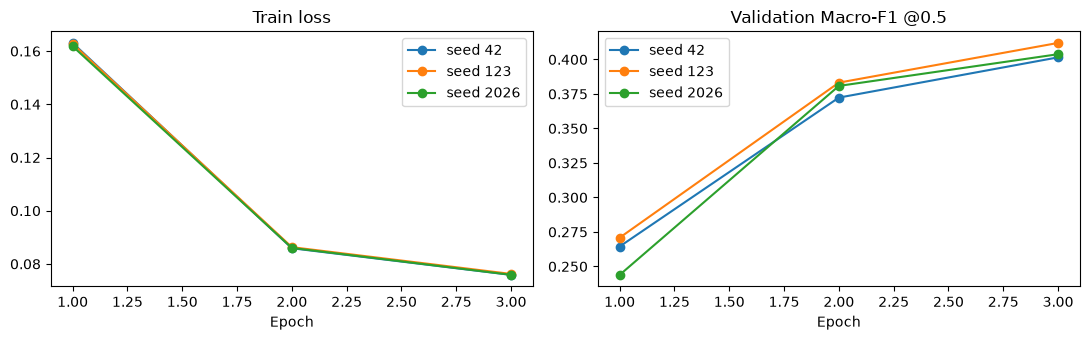

Epoch tốt nhất được ghi theo từng seed; chưa khẳng định siêu tham số tối ưu.


In [3]:
import matplotlib.pyplot as plt
history = pd.DataFrame([dict(seed=seed, selected_epoch=meta['selected_epoch'], **row)
                       for seed, meta in runs.items() for row in meta['history']])
display(history)
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
for seed, group in history.groupby('seed'):
    axes[0].plot(group.epoch, group.train_loss, marker='o', label=f'seed {seed}')
    axes[1].plot(group.epoch, group.macro_f1, marker='o', label=f'seed {seed}')
axes[0].set_title('Train loss'); axes[1].set_title('Validation Macro-F1 @0.5')
for ax in axes: ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.show(); plt.close()
print('Epoch tốt nhất được ghi theo từng seed; chưa khẳng định siêu tham số tối ưu.')

## 3. Theo dõi tokenizer và BCE bằng một batch train thật
CLS → encoder 6 block → pre_classifier → ReLU → dropout → classifier 28 logits.
Distillation thuộc pretraining; nhóm fine-tune bằng BCE. Cell không gọi backward.

In [4]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scripts.transformers.train_transformer import encoded_dataset, trim_padding_collate
folder = run_folder(ARTIFACTS, 'distilbert', 42)
tokenizer = AutoTokenizer.from_pretrained(folder/'checkpoint', local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(folder/'checkpoint', local_files_only=True).eval()
data, _ = encoded_dataset(frames['train'].head(4), tokenizer, names, runs[42]['config']['max_length'])
batch = trim_padding_collate([data[i] for i in range(4)])
with torch.inference_mode():
    out = model(**batch)
    expected = torch.nn.functional.binary_cross_entropy_with_logits(out.logits, batch['labels'])
torch.testing.assert_close(out.loss, expected)
display(pd.Series(dict(input_shape=str(tuple(batch['input_ids'].shape)),
    labels_shape=str(tuple(batch['labels'].shape)), logits_shape=str(tuple(out.logits.shape)), bce=float(out.loss))))
display(pd.DataFrame({'token':tokenizer.convert_ids_to_tokens(batch['input_ids'][0]),
                      'id':batch['input_ids'][0].tolist()}))
del model, data, batch, out

D:\Nam_3\HK1\NLP\LT\goemotions-multilabel-classification\.venv-huy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


input_shape      (4, 24)
labels_shape     (4, 28)
logits_shape     (4, 28)
bce             0.056296
dtype: object

,token,id
0,[CLS],101
1,my,2026
2,favourite,8837
3,food,2833
4,is,2003
5,anything,2505
6,i,1045
7,didn,2134
8,',1005
9,t,1056


## 4. Code huấn luyện dùng cho lượt chạy này

In [5]:
import inspect
from IPython.display import Code
from scripts.transformers import train_transformer
display(Code(inspect.getsource(train_transformer.main), language='python'))

def main():
    # BƯỚC 1 — Cấu hình và thư mục; resume chỉ bỏ qua run đã hoàn tất đúng hash.
    configure_console()
    args = parse_args()
    config = training_config(args.architecture, smoke=args.smoke, weighted=args.weighted,
                             epochs=args.epochs, learning_rate=args.learning_rate,
                             batch_size=args.batch_size, gradient_accumulation=args.gradient_accumulation,
                             max_length=args.max_length, device=args.device, revision=args.revision)
    output = run_folder(ROOT, args.architecture, args.seed, smoke=args.smoke, weighted=args.weighted)
    metadata_path = output / "run_metadata.json"
    if metadata_path.exists() and args.resume:
        previous = json.loads(metadata_path.read_text(encoding="utf-8"))
        if previous.get("completed"):
            previous = load_transformer_run(output, require_full=not args.smoke, expected_config=config)
            if previous["architecture"] != args.architecture or previous["seed"] != args.seed:
                raise ValueError("Run có seed/kiến trúc khác")
            print(f"Đã hoàn tất, hash/config đúng; bỏ qua {output}", flush=True)
            return
        if not args.overwrite:
            raise RuntimeError("Run này bị ngắt trước khi hoàn tất. Chạy lại đúng seed với "
                               "--overwrite; có thể kết hợp --resume để bỏ qua các seed đã xong.")
    if output.exists() and any(output.iterdir()) and not args.overwrite:
        raise FileExistsError(f"Run đã có dữ liệu: {output}. Dùng --resume hoặc --overwrite.")

    # Imports nặng nằm sau phần argparse/resume: --help không cần GPU/checkpoint.
    import torch
    import transformers
    from huggingface_hub import HfApi
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

    seed_everything(args.seed)
    torch.set_num_threads(4)  # Tránh quá nhiều CPU threads trên Windows 16 GB RAM.
    device = resolve_device(args.device)
    amp_enabled = device.type == "cuda"
    # Khóa cùng SHA cho tokenizer và encoder; không bật remote custom code.
    revision = HfApi().model_info(config["checkpoint"], revision=args.revision).sha
    if not revision:
        raise RuntimeError("Không resolve được commit SHA của checkpoint")
    started = time.perf_counter()
    frames, labels, manifest = load_goemotions(ROOT, write_metadata=False,
                                              splits=("train", "validation"))
    if labels != json.loads((ROOT / "data/labels.json").read_text(encoding="utf-8")):
        raise ValueError("Mapping dữ liệu không khớp data/labels.json")
    train = frames["train"].iloc[:64] if args.smoke else frames["train"]
    validation = frames["validation"].iloc[:32] if args.smoke else frames["validation"]
    if (train["id"].duplicated().any() or validation["id"].duplicated().any() or
            set(train["id"]) & set(validation["id"])):
        raise ValueError("ID trùng trong/between train và validation")
    if any(frame["text"].isna().any() or frame["text"].str.strip().eq("").any()
           for frame in (train, validation)):
        raise ValueError("Train/validation có câu rỗng")
    # BƯỚC 2 — Cùng revision, mapping và độ dài token ở train/validation/inference.
    tokenizer = AutoTokenizer.from_pretrained(config["checkpoint"], revision=revision,
                                               trust_remote_code=False)
    train_data, y_train = encoded_dataset(train, tokenizer, labels, args.max_length)
    validation_data, y_validation = encoded_dataset(validation, tokenizer, labels, args.max_length)
    generator = torch.Generator().manual_seed(args.seed)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=args.batch_size,
                                               shuffle=True, generator=generator, num_workers=0,
                                               pin_memory=amp_enabled, collate_fn=trim_padding_collate)
    validation_load

## 5. Suy luận lại cả validation và test từ ba checkpoint
Mỗi split chạy đủ mẫu, giữ nguyên ngưỡng đã khóa. Dừng nếu metric không khớp
artifact. Không lấy số từ bảng xuất sẵn để giả làm kết quả suy luận mới.

In [6]:
parts = []
for seed in SEEDS:
    for split in ('validation','test'):
        parts.append(replay_split(ARTIFACTS, 'C_distilbert', seed, split))
        print('PASS real inference:', seed, split, len(frames[split]))
fresh = pd.concat(parts, ignore_index=True)
assert len(fresh) == 18
display(fresh)

PASS real inference: 42 validation 5426


PASS real inference: 42 test 5427


PASS real inference: 123 validation 5426


PASS real inference: 123 test 5427


PASS real inference: 2026 validation 5426


PASS real inference: 2026 test 5427


,system,seed,split,threshold_mode,n_samples,macro_f1,micro_f1,macro_precision,macro_recall,micro_precision,micro_recall,hamming_loss,metric_max_abs_diff,score_max_abs_diff
0,C_distilbert,42,validation,fixed,5426,0.401537,0.568959,0.573599,0.341646,0.710131,0.474608,0.030199,0.0,0.0
1,C_distilbert,42,validation,global,5426,0.476153,0.597541,0.500946,0.526676,0.529540,0.685580,0.038782,0.0,0.0
2,C_distilbert,42,validation,tuned,5426,0.514735,0.602538,0.512817,0.541270,0.550019,0.666144,0.036906,0.0,0.0
3,C_distilbert,42,test,fixed,5427,0.416795,0.573216,0.591906,0.356420,0.716248,0.477801,0.029634,0.0,0.0
4,C_distilbert,42,test,global,5427,0.466461,0.596857,0.473013,0.522312,0.524140,0.693000,0.038992,0.0,0.0
5,C_distilbert,42,test,tuned,5427,0.488476,0.595143,0.489470,0.521679,0.540426,0.662190,0.037524,0.0,0.0
6,C_distilbert,123,validation,fixed,5426,0.411993,0.577479,0.577245,0.352092,0.713298,0.485110,0.029810,0.0,0.0
7,C_distilbert,123,validation,global,5426,0.478423,0.581385,0.463090,0.570934,0.484386,0.726959,0.043962,0.0,0.0
8,C_distilbert,123,validation,tuned,5426,0.508281,0.607466,0.541177,0.516587,0.560397,0.663166,0.035991,0.0,0.0
9,C_distilbert,123,test,fixed,5427,0.417538,0.578097,0.602040,0.358091,0.719088,0.483331,0.029384,0.0,0.0


## 6. Mean và sample std qua ba seed

In [7]:
averages = summarize(fresh.to_dict('records'))
for row in averages:
    expected = next(r for r in verified['averages'] if r['system']=='C_distilbert'
                    and r['split']==row['split'] and r['threshold_mode']==row['threshold_mode'])
    for metric in METRIC_NAMES:
        for suffix in ('_mean','_std'):
            assert abs(row[metric+suffix]-expected[metric+suffix]) <= 1e-12
display(pd.DataFrame(averages)[['split','threshold_mode','n_runs','macro_f1_mean','macro_f1_std',
                              'micro_f1_mean','micro_f1_std','hamming_loss_mean']])
print('PASS: sáu nhóm mean ± sample std (ddof=1) từ ba seed thật.')

,split,threshold_mode,n_runs,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std,hamming_loss_mean
0,validation,fixed,3,0.405782,0.005498,0.573810,0.004381,0.030019
1,validation,global,3,0.475658,0.003042,0.592041,0.009230,0.040447
2,validation,tuned,3,0.510483,0.003683,0.604067,0.002948,0.036366
3,test,fixed,3,0.415353,0.003163,0.575894,0.002475,0.029559
4,test,global,3,0.464222,0.001971,0.590658,0.011384,0.040755
5,test,tuned,3,0.490719,0.009303,0.597361,0.002280,0.036980


PASS: sáu nhóm mean ± sample std (ddof=1) từ ba seed thật.


## 7. Ngưỡng riêng và năm nhãn hiếm
Chọn năm nhãn có support train thấp nhất. So fixed/global/tuned trên cùng model;
hiển thị cả nhãn tăng và giảm điểm, không có thí nghiệm weighted BCE ở đây.

In [8]:
from src.models.baseline import load_aligned_scores
support = multi_hot(frames['train'].labels.tolist()).sum(axis=0)
rare_ids = np.argsort(support)[:5].tolist()
threshold_rows, rare_rows = [], []
for seed in SEEDS:
    folder = run_folder(ARTIFACTS, 'distilbert', seed)
    protocol = read_json(folder/'final_protocol.json')
    scores = load_aligned_scores(ROOT/f'reports/notebook_replay/C_distilbert_{seed}_test.npz', frames['test'].id, names)
    truth = multi_hot(frames['test'].labels.tolist())
    for choice in protocol['configurations']:
        metric = evaluate_multilabel(truth, scores, names, choice['thresholds'])
        rare_rows.extend(dict(seed=seed, mode=choice['threshold_mode'], **metric['per_label'][j]) for j in rare_ids)
        if choice['threshold_mode']=='tuned':
            threshold_rows.extend(dict(seed=seed,label=label,threshold=value) for label,value in zip(names,choice['thresholds']))
display(pd.DataFrame(threshold_rows).pivot(index='label',columns='seed',values='threshold').reindex(names))
display(pd.DataFrame(rare_rows).groupby(['label','mode']).f1.agg(['mean','std']))

seed,42,123,2026
label,,,
admiration,0.40,0.40,0.40
amusement,0.30,0.25,0.45
anger,0.30,0.35,0.30
annoyance,0.20,0.20,0.20
approval,0.15,0.20,0.20
caring,0.20,0.35,0.20
confusion,0.25,0.25,0.25
curiosity,0.20,0.25,0.25
desire,0.35,0.20,0.35


mean       std
label         mode                      
embarrassment fixed   0.145606  0.045243
              global  0.444500  0.062144
              tuned   0.394774  0.106681
grief         fixed   0.000000  0.000000
              global  0.000000  0.000000
              tuned   0.000000  0.000000
nervousness   fixed   0.000000  0.000000
              global  0.155644  0.088657
              tuned   0.321852  0.062265
pride         fixed   0.000000  0.000000
              global  0.078431  0.067924
              tuned   0.467564  0.075791
relief        fixed   0.000000  0.000000
              global  0.000000  0.000000
              tuned   0.062500  0.108253

## 8. Ba nhóm lỗi và ví dụ có ID
Seed đại diện chọn bằng validation; fixed 0,5. Các nhóm có thể chồng lấp:
thiếu một phần nhãn, bỏ sót nhãn hiếm, vừa bỏ sót vừa dự đoán thừa.

In [9]:
from scripts.analysis.analyze_project_errors import analyze_arrays
seed = max(SEEDS, key=lambda s:(runs[s]['metrics']['macro_f1'], -s))
scores = load_aligned_scores(ROOT/f'reports/notebook_replay/C_distilbert_{seed}_test.npz', frames['test'].id, names)
counts, pairs, rare, examples = analyze_arrays(frames['test'], names, rare_ids, support,
    {'distilbert':runs[seed]}, {'distilbert':scores}, {'distilbert':0.5})
display(pd.DataFrame(counts))
display(pd.DataFrame(examples))
print('Seed đại diện C3 theo validation:', seed)

,architecture,seed,category,error_samples,total_samples,eligible_samples,fraction_all_samples,fraction_eligible
0,distilbert,123,partial_multi_label,473,5427,837,0.087157,0.565114
1,distilbert,123,rare_false_negative,89,5427,93,0.016399,0.956989
2,distilbert,123,missed_extra_pair,1131,5427,5427,0.208402,0.208402


,category,id,architecture,seed,error_present,text,true_labels,predicted_labels,missed_labels,extra_labels,scores_by_label,manual_linguistic_notes
0,partial_multi_label,eczj48j,distilbert,123,True,This!!! 🐃 and 💍 for your hard work!,"[""admiration"", ""excitement"", ""neutral""]","[""admiration""]","[""excitement"", ""neutral""]",[],"{""admiration"": 0.6989462971687317, ""amusement""...",
1,partial_multi_label,eczje98,distilbert,123,True,I love this! It's nice to hear of a positive o...,"[""admiration"", ""love""]","[""love""]","[""admiration""]",[],"{""admiration"": 0.35242462158203125, ""amusement...",
2,partial_multi_label,eczs4ty,distilbert,123,True,I'm sorry to hear this. I hope you can find so...,"[""optimism"", ""remorse""]","[""optimism""]","[""remorse""]",[],"{""admiration"": 0.02241421490907669, ""amusement...",
3,partial_multi_label,eczyqul,distilbert,123,True,That's really interesting. Thank you for the i...,"[""excitement"", ""gratitude""]","[""admiration"", ""gratitude""]","[""excitement""]","[""admiration""]","{""admiration"": 0.583737313747406, ""amusement"":...",
4,partial_multi_label,ed0p7or,distilbert,123,True,"Vitamin C is water soluble, you literally piss...","[""annoyance"", ""neutral""]","[""neutral""]","[""annoyance""]",[],"{""admiration"": 0.003285833168774843, ""amusemen...",
5,rare_false_negative,ed0jr9i,distilbert,123,True,Try nonchalantly handing them your card as if ...,"[""embarrassment""]",[],"[""embarrassment""]",[],"{""admiration"": 0.0015487611526623368, ""amuseme...",
6,rare_false_negative,ed0wflq,distilbert,123,True,I was teased for being a virgin when I was a 6...,"[""embarrassment""]",[],"[""embarrassment""]",[],"{""admiration"": 0.0033634924329817295, ""amuseme...",
7,rare_false_negative,ed157d1,distilbert,123,True,I feel a sense of unease tbh,"[""nervousness""]",[],"[""nervousness""]",[],"{""admiration"": 0.0015070488443598151, ""amuseme...",
8,rare_false_negative,ed219du,distilbert,123,True,Didn't that used to be the Northern Bank build...,"[""curiosity"", ""embarrassment""]",[],"[""curiosity"", ""embarrassment""]",[],"{""admiration"": 0.002123966347426176, ""amusemen...",
9,rare_false_negative,ed23cfo,distilbert,123,True,I’d be verrrrrrrry nervous if we hired him. Wo...,"[""love"", ""nervousness""]","[""love""]","[""nervousness""]",[],"{""admiration"": 0.023286305367946625, ""amusemen...",


Seed đại diện C3 theo validation: 123


## 9. Dự đoán câu nhập và phân biệt với demo chung
Dùng checkpoint C3 đại diện để thử câu. Demo chung chọn kiến trúc theo mean validation
Macro-F1 của cả ba C; kết quả chọn được đọc từ selected_model, không hard-code BERT123.

In [10]:
from src.apps.demo import TransformerDemo
folder = run_folder(ARTIFACTS, 'distilbert', seed)
predictor = TransformerDemo.from_checked_checkpoint(folder/'checkpoint', runs[seed], 'auto')
for text in ['Thank you, I am so happy!', 'Why did this happen?']:
    message, rows = predictor.predict(text)
    print(text, message)
    assert len(rows) == 28
    display(pd.DataFrame(rows, columns=['label','score','threshold','selected']))
del predictor
if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Demo chính:', verified['selection']['architecture'], 'seed', verified['selection']['seed'])
print('Hoàn tất: 3 checkpoint C3 full, 6 lượt suy luận, 18 dòng metric; không train trong Run All.')

Thank you, I am so happy! **Cảm xúc dự đoán:** gratitude, joy


,label,score,threshold,selected
0,gratitude,0.9424,0.5,Có
1,joy,0.5590,0.5,Có
2,excitement,0.0502,0.5,
3,admiration,0.0439,0.5,
4,amusement,0.0178,0.5,
5,caring,0.0139,0.5,
6,approval,0.0131,0.5,
7,optimism,0.0129,0.5,
8,relief,0.0113,0.5,
9,love,0.0091,0.5,


Why did this happen? **Chưa có nhãn nào đạt ngưỡng.** Không tự suy ra neutral trong trường hợp này.


,label,score,threshold,selected
0,curiosity,0.4766,0.5,
1,neutral,0.3310,0.5,
2,confusion,0.1985,0.5,
3,annoyance,0.0170,0.5,
4,disapproval,0.0067,0.5,
5,surprise,0.0051,0.5,
6,anger,0.0043,0.5,
7,realization,0.0041,0.5,
8,disappointment,0.0037,0.5,
9,approval,0.0026,0.5,


Demo chính: bert seed 123
Hoàn tất: 3 checkpoint C3 full, 6 lượt suy luận, 18 dòng metric; không train trong Run All.
